In [4]:
import pandas as pd

print(pd.__version__)

3.1.1


In [5]:
import pandas as pd

# 1. Load only the five variables we want to inspect
DATA_FILE = "../data/WVS_Cross-National_Wave_7_csv_v6_0.csv"

variables = ["Q49", "Q57", "Q58", "Q59", "Q288"]

country_column = "B_COUNTRY_ALPHA"

columns_to_load = variables + [country_column]

df = pd.read_csv(
    DATA_FILE,
    usecols=columns_to_load
)

print(df.columns.tolist())

# 2. Define the codes we want to inspect
special_codes = [-1, -2, -3, -4, -5]

# 3. Create a report
report = []

for variable in variables:

    counts = df[variable].value_counts(dropna=False)

    total = len(df)

    row = {
        "Variable": variable,
        "Total respondents": total,
        "NaN": df[variable].isna().sum()
    }

    for code in special_codes:
        row[f"Code {code}"] = counts.get(code, 0)

    row["Valid responses"] = (
        total
        - row["NaN"]
        - sum(row[f"Code {code}"] for code in special_codes)
    )

    row["Valid percentage"] = (
        row["Valid responses"] / total * 100
    )

    report.append(row)


# 4. Convert results into a DataFrame
report_df = pd.DataFrame(report)

# 5. Display results
print("\nSPECIAL CODE INSPECTION")
print("=" * 80)

print(report_df.to_string(index=False))

# 6. Save report
report_df.to_csv(
    "WVS_special_code_inspection.csv",
    index=False
)

# 7. Check valid value ranges

expected_ranges = {
    "Q49": list(range(1, 11)),
    "Q57": [1, 2],
    "Q58": [1, 2, 3, 4],
    "Q59": [1, 2, 3, 4]
}

print("\nVALID VALUE RANGE INSPECTION")
print("=" * 80)

for variable, expected_values in expected_ranges.items():

    actual_values = sorted(
        df[variable].dropna().unique()
    )

    valid_values = [
        value for value in actual_values
        if value in expected_values
    ]

    unexpected_values = [
        value for value in actual_values
        if value not in expected_values
        and value not in special_codes
    ]

    print(f"\nVariable: {variable}")
    print(f"Expected values: {expected_values}")
    print(f"Actual values: {actual_values}")
    print(f"Unexpected values: {unexpected_values}")

print("\nReport saved successfully!")

['B_COUNTRY_ALPHA', 'Q49', 'Q57', 'Q58', 'Q59', 'Q288']

SPECIAL CODE INSPECTION
Variable  Total respondents  NaN  Code -1  Code -2  Code -3  Code -4  Code -5  Valid responses  Valid percentage
     Q49              97220    0      205      203        0        0      112            96700         99.465131
     Q57              97220    0      737      310        0        0      290            95883         98.624769
     Q58              97220    0      102      125        0        0      105            96888         99.658506
     Q59              97220    0      534      184        0        0      109            96393         99.149352
    Q288              97220    0     1046     1585        0        0      330            94259         96.954330

VALID VALUE RANGE INSPECTION

Variable: Q49
Expected values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Actual values: [np.int64(-5), np.int64(-2), np.int64(-1), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)

In [6]:
import numpy as np

# Create a copy of the original data
df_clean = df.copy()

# Replace confirmed special codes with NaN
codes_to_replace = [-1, -2, -5]

df_clean[variables] = df_clean[variables].replace(
    codes_to_replace,
    np.nan
)

# Check the result
print("\nMISSING VALUES AFTER CLEANING")
print("=" * 60)

print(df_clean[variables].isna().sum())

print("\nVALID VALUE COUNTS")
print("=" * 60)

print(df_clean[variables].count())


MISSING VALUES AFTER CLEANING
Q49      520
Q57     1337
Q58      332
Q59      827
Q288    2961
dtype: int64

VALID VALUE COUNTS
Q49     96700
Q57     95883
Q58     96888
Q59     96393
Q288    94259
dtype: int64


In [7]:
# Complete Case Analysis experiment

selected_variables = [
    "Q49",
    "Q57",
    "Q58",
    "Q59",
    "Q288"
]

df_complete = df_clean.dropna(
    subset=selected_variables
)

print("\nCOMPLETE CASE ANALYSIS")
print("=" * 60)

print("Original respondents:", len(df_clean))
print("Complete cases:", len(df_complete))

removed = len(df_clean) - len(df_complete)

print("Removed respondents:", removed)

retention = len(df_complete) / len(df_clean) * 100

print(f"Sample retention rate: {retention:.2f}%")


COMPLETE CASE ANALYSIS
Original respondents: 97220
Complete cases: 92248
Removed respondents: 4972
Sample retention rate: 94.89%


In [ ]:
# COUNTRY-LEVEL MISSING VALUE ANALYSIS

country_column = "B_COUNTRY_ALPHA"

analysis_df = df_clean.copy()

analysis_df["is_complete"] = (
    analysis_df[selected_variables]
    .notna()
    .all(axis=1)
)

country_report = (
    analysis_df
    .groupby(country_column)
    .agg(
        total_respondents=("is_complete", "size"),
        complete_cases=("is_complete", "sum")
    )
    .reset_index()
)

country_report["removed_respondents"] = (
    country_report["total_respondents"]
    - country_report["complete_cases"]
)

country_report["retention_rate"] = (
    country_report["complete_cases"]
    / country_report["total_respondents"] * 100
)

country_report["sample_loss_rate"] = (
    100 - country_report["retention_rate"]
)

country_report = country_report.sort_values(
    "retention_rate"
)

print("\nCOUNTRY-LEVEL COMPLETE CASE ANALYSIS")
print("=" * 80)

print(country_report.to_string(index=False))

country_report.to_csv(
    "../WVS_country_missing_analysis.csv",
    index=False
)


COUNTRY-LEVEL COMPLETE CASE ANALYSIS
B_COUNTRY_ALPHA  total_respondents  complete_cases  removed_respondents  retention_rate  sample_loss_rate
            NLD               2145            1521                  624       70.909091         29.090909
            NIR                447             355                   92       79.418345         20.581655
            JPN               1353            1078                  275       79.674797         20.325203
            GBR               2609            2096                  513       80.337294         19.662706
            NZL               1057             850                  207       80.416272         19.583728
            AND               1004             878                  126       87.450199         12.549801
            UZB               1250            1099                  151       87.920000         12.080000
            ARG               1003             896                  107       89.332004         10.667996
        

In [9]:
df_clean = df.copy()

codes_to_replace = [-1, -2, -5]

df_clean[variables] = df_clean[variables].replace(
    codes_to_replace,
    np.nan
)

In [12]:
# 1. Calculate missing rate by country and variable

missing_by_country = (
    df_clean
    .groupby(country_column)[variables]
    .apply(lambda x: x.isna().mean() * 100)
)

# 2. Display results

print("\nMISSING RATE BY COUNTRY AND VARIABLE")
print("=" * 100)

print(missing_by_country.round(2).to_string())

# 3. Export results

missing_by_country.to_csv(
    "../WVS_analysis_output/missing_rate_by_country.csv"
)


MISSING RATE BY COUNTRY AND VARIABLE
                  Q49   Q57   Q58   Q59   Q288
B_COUNTRY_ALPHA                               
AND              0.20  0.30  0.00  0.10  12.05
ARG              0.00  5.08  0.20  1.30   4.89
ARM              0.25  0.16  0.65  1.55   0.90
AUS              0.88  1.16  0.61  1.10   3.59
BGD              0.00  0.08  0.08  0.08   0.00
BOL              0.44  0.97  0.05  0.19   2.61
BRA              0.45  1.82  0.57  2.21   6.81
CAN              0.00  0.00  0.00  0.00   0.00
CHL              0.90  2.60  0.10  0.60   2.60
CHN              0.40  0.89  0.30  0.33   0.86
COL              0.00  0.00  0.00  0.00   0.00
CYP              0.40  4.00  0.50  2.00   6.10
CZE              0.00  0.75  0.25  0.08   1.17
DEU              0.33  3.01  0.33  1.44   3.53
ECU              0.17  1.92  0.17  0.17   0.83
EGY              0.25  0.25  0.00  0.08   7.17
ETH              0.08  0.33  0.00  0.08   0.16
GBR              0.57  1.61  0.31  1.19  17.17
GRC              0.00 


Q288 VALUE COUNTS
Q288
-5       330
-2      1585
-1      1046
 1      7277
 2      5502
 3     10587
 4     13148
 5     22535
 6     14527
 7     11008
 8      5801
 9      1828
 10     2046
Name: count, dtype: int64

Q288 UNIQUE VALUES
[np.int64(-5), np.int64(-2), np.int64(-1), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


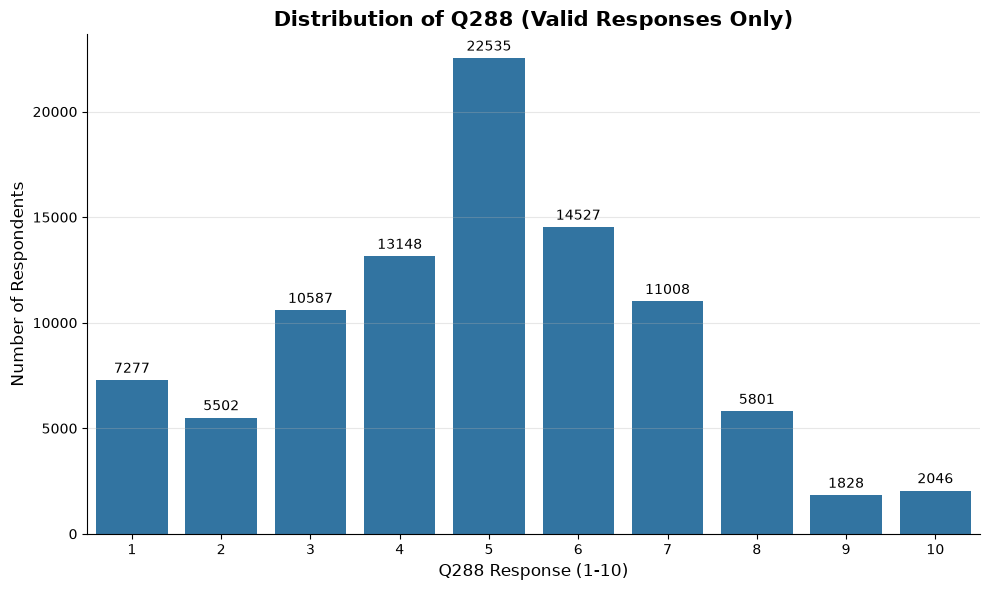

In [ ]:
# Inspect Q288 values

print("\nQ288 VALUE COUNTS")
print("=" * 50)

print(df["Q288"].value_counts().sort_index())

print("\nQ288 UNIQUE VALUES")
print(sorted(df["Q288"].unique()))

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Keep only valid responses (1-10)
q288_valid = df.loc[
    df["Q288"].between(1, 10),
    "Q288"
]

# 2. Count valid responses
q288_counts = q288_valid.value_counts().sort_index()

# 3. Create bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=q288_counts.index.astype(str),
    y=q288_counts.values
)

# 4. Add title and labels
ax.set_title(
    "Distribution of Q288 (Valid Responses Only)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Q288 Response (1-10)", fontsize=12)
ax.set_ylabel("Number of Respondents", fontsize=12)

# 5. Display values above bars
ax.bar_label(ax.containers[0], padding=3)

# 6. Styling
sns.despine()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# 7. Save chart
plt.savefig(
    "../WVS_analysis_output/Q288_valid_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# Check actual missing values (NaN)

print("NaN count per variable:")
print(df.isna().sum().sort_values(ascending=False).head(20))



NaN count per variable:
B_COUNTRY_ALPHA    0
Q49                0
Q57                0
Q58                0
Q59                0
Q288               0
dtype: int64


## Preliminary Feature Discovery

### Objective
Identify survey-related variables that may be suitable
for exploratory analysis of their association with Q49 (Life Satisfaction).

This stage focuses on variable screening, not data cleaning
or correlation analysis.

In [18]:
import pandas as pd

INVENTORY_FILE = "../WVS_analysis_output/WVS_variable_inventory.csv"

inventory = pd.read_csv(INVENTORY_FILE)

print("Inventory shape:", inventory.shape)

display(inventory.head())

Inventory shape: (613, 10)


,Column number,Variable,Data type,Missing count (NaN),Missing percentage (NaN),Unique values (excluding NaN),Candidate special-code count,Candidate special-code details,Example values,Preliminary category
0,1,version,str,0,0.0,1,0,NaN,6-0-0 (2024-04-30),Other / requires codebook review
1,2,doi,str,0,0.0,1,0,NaN,doi.org/10.14281/18241.24,Other / requires codebook review
2,3,A_WAVE,int64,0,0.0,1,0,NaN,7,Survey metadata / sampling / respondent context
3,4,A_YEAR,int64,0,0.0,7,0,NaN,2018 | 2017 | 2021 | 2020 | 2019 | 2022 | 2023,Survey metadata / sampling / respondent context
4,5,A_STUDY,int64,0,0.0,1,0,NaN,2,Survey metadata / sampling / respondent context


In [19]:
# First-round screening: survey-related variables

survey_variables = inventory[
    inventory["Preliminary category"]
    == "Survey question / question-derived field"
].copy()

print("Total variables:", len(inventory))
print("Survey-related variables:", len(survey_variables))

display(survey_variables.head(10))

Total variables: 613
Survey-related variables: 372


,Column number,Variable,Data type,Missing count (NaN),Missing percentage (NaN),Unique values (excluding NaN),Candidate special-code count,Candidate special-code details,Example values,Preliminary category
40,41,Q1,int64,0,0.0,7,155,-1: 27; -2: 61; -5: 67,1 | 2 | 3 | 4 | -2 | -1 | -5,Survey question / question-derived field
41,42,Q2,int64,0,0.0,7,312,-1: 84; -2: 141; -5: 87,1 | 2 | 3 | 4 | -1 | -2 | -5,Survey question / question-derived field
42,43,Q3,int64,0,0.0,7,535,-1: 202; -2: 196; -5: 137,1 | 2 | 3 | 4 | -1 | -2 | -5,Survey question / question-derived field
43,44,Q4,int64,0,0.0,7,1090,-1: 587; -2: 323; -5: 180,3 | 4 | 2 | 1 | -2 | -1 | -5,Survey question / question-derived field
44,45,Q5,int64,0,0.0,7,1160,-1: 368; -2: 289; -5: 503,1 | 3 | 2 | 4 | -2 | -1 | -5,Survey question / question-derived field
45,46,Q6,int64,0,0.0,7,926,-1: 402; -2: 269; -5: 255,4 | 3 | 2 | 1 | -2 | -1 | -5,Survey question / question-derived field
46,47,Q7,int64,0,0.0,5,397,-1: 122; -2: 172; -5: 103,1 | 2 | -2 | -1 | -5,Survey question / question-derived field
47,48,Q8,int64,0,0.0,5,1038,-1: 464; -2: 481; -5: 93,1 | 2 | -2 | -1 | -5,Survey question / question-derived field
48,49,Q9,int64,0,0.0,5,692,-1: 193; -2: 406; -5: 93,2 | 1 | -2 | -1 | -5,Survey question / question-derived field
49,50,Q10,int64,0,0.0,5,553,-1: 200; -2: 260; -5: 93,1 | 2 | -2 | -1 | -5,Survey question / question-derived field


In [20]:
# Inspect data quality of survey-related variables

quality_summary = survey_variables[
    [
        "Variable",
        "Data type",
        "Missing percentage (NaN)",
        "Unique values (excluding NaN)",
        "Candidate special-code count",
        "Candidate special-code details"
    ]
].copy()

display(
    quality_summary.sort_values(
        by="Missing percentage (NaN)",
        ascending=False
    ).head(30)
)

,Variable,Data type,Missing percentage (NaN),Unique values (excluding NaN),Candidate special-code count,Candidate special-code details
40,Q1,int64,0.0,7,155,-1: 27; -2: 61; -5: 67
41,Q2,int64,0.0,7,312,-1: 84; -2: 141; -5: 87
42,Q3,int64,0.0,7,535,-1: 202; -2: 196; -5: 137
43,Q4,int64,0.0,7,1090,-1: 587; -2: 323; -5: 180
44,Q5,int64,0.0,7,1160,-1: 368; -2: 289; -5: 503
45,Q6,int64,0.0,7,926,-1: 402; -2: 269; -5: 255
46,Q7,int64,0.0,5,397,-1: 122; -2: 172; -5: 103
47,Q8,int64,0.0,5,1038,-1: 464; -2: 481; -5: 93
48,Q9,int64,0.0,5,692,-1: 193; -2: 406; -5: 93
49,Q10,int64,0.0,5,553,-1: 200; -2: 260; -5: 93


In [21]:
# Count variables by data type

print("\nDATA TYPE DISTRIBUTION")
print("=" * 50)

print(
    survey_variables["Data type"]
    .value_counts()
)


DATA TYPE DISTRIBUTION
Data type
int64    372
Name: count, dtype: int64


In [22]:
# Distribution of unique values

print("\nUNIQUE VALUE DISTRIBUTION")
print("=" * 50)

unique_distribution = (
    survey_variables["Unique values (excluding NaN)"]
    .value_counts()
    .sort_index()
)

print(unique_distribution)


UNIQUE VALUE DISTRIBUTION
Unique values (excluding NaN)
5      37
6      54
7      79
8      78
9      41
10      2
11      2
12      1
13     27
14     26
15      5
16      1
17      2
27      1
36      1
89      1
92      1
122     1
158     2
163     1
173     1
379     1
385     1
388     1
409     1
437     1
630     3
Name: count, dtype: int64


In [23]:
# Identify variables with more than 20 unique values

high_unique_variables = survey_variables[
    survey_variables["Unique values (excluding NaN)"] > 20
].copy()

high_unique_variables = high_unique_variables.sort_values(
    by="Unique values (excluding NaN)",
    ascending=False
)

print("Variables with more than 20 unique values:",
      len(high_unique_variables))

display(
    high_unique_variables[
        [
            "Variable",
            "Unique values (excluding NaN)",
            "Candidate special-code count",
            "Candidate special-code details",
            "Example values"
        ]
    ]
)

Variables with more than 20 unique values: 17


,Variable,Unique values (excluding NaN),Candidate special-code count,Candidate special-code details,Example values
295,Q223,630,24779,-1: 10193; -2: 5974; -3: 629; -4: 6248; -5: 1735,20001 | 2 | 20005 | -2 | 20006 | 5 | 20008 | 2...
296,Q223_ABREV,630,24779,-1: 10193; -2: 5974; -3: 629; -4: 6248; -5: 1735,20001 | 2 | 20005 | -2 | 20006 | 5 | 20008 | 2...
297,Q223_LOCAL,630,24779,-1: 10193; -2: 5974; -3: 629; -4: 6248; -5: 1735,20001 | 2 | 20005 | -2 | 20006 | 5 | 20008 | 2...
382,Q290,437,9601,-1: 314; -2: 295; -3: 89; -4: 6341; -5: 2562,20001 | 20999 | 20002 | 20005 | 20004 | 20003 ...
358,Q275A,409,43023,-1: 54; -2: 341; -3: 163; -4: 40926; -5: 1539,20003 | 20007 | 20002 | 20001 | 20004 | 20005 ...
361,Q276A,388,63008,-1: 215; -2: 1548; -3: 16975; -4: 43982; -5: 288,20003 | 20006 | -3 | 20002 | 20001 | 20007 | 2...
367,Q278A,385,50296,-1: 2418; -2: 1479; -3: 115; -4: 43982; -5: 2302,20003 | 20006 | 20001 | 20000 | -2 | 20007 | 2...
364,Q277A,379,49628,-1: 2028; -2: 1342; -3: 111; -4: 43982; -5: 2165,20003 | 20005 | 20001 | 20000 | -2 | 20006 | 2...
354,Q272,173,2720,-1: 19; -2: 114; -4: 2415; -5: 172,1270 | 810 | 3530 | 9040 | 9000 | 1400 | 200 |...
347,Q267,163,7459,-1: 83; -2: 969; -4: 6092; -5: 315,724 | 620 | 170 | 20 | 818 | 250 | 300 | 484


In [24]:
# Extract questionnaire descriptions for high-unique variables

high_unique_names = high_unique_variables["Variable"].tolist()

print("Variables to investigate:")
print(high_unique_names)

Variables to investigate:
['Q223', 'Q223_ABREV', 'Q223_LOCAL', 'Q290', 'Q275A', 'Q276A', 'Q278A', 'Q277A', 'Q272', 'Q267', 'Q266', 'Q268', 'Q289CS9', 'Q261', 'Q262', 'Q270', 'Q274']


In [25]:
# Create a dictionary of variable descriptions based on the WVS Codebook

variable_descriptions = {
    "Q223": "Political party choice (country-specific list)",
    "Q223_ABREV": "Not independently confirmed in Codebook",
    "Q223_LOCAL": "Not independently confirmed in Codebook",
    "Q290": "Racial / ethnic belonging (country-specific)",
    "Q275A": "Respondent's education (country-specific)",
    "Q276A": "Spouse's education (country-specific)",
    "Q277A": "Mother's education (country-specific)",
    "Q278A": "Father's education (country-specific)",
    "Q272": "Language normally spoken at home",
    "Q267": "Mother's country of birth",
    "Q266": "Respondent's country of birth",
    "Q268": "Father's country of birth",
    "Q261": "Year of birth",
    "Q262": "Age",
    "Q270": "Number of people in household",
    "Q274": "Number of children",
    "Q289CS9": "Exact field correspondence not yet confirmed"
}

# Add descriptions to the high-unique variable table
high_unique_variables["Codebook description"] = (
    high_unique_variables["Variable"].map(variable_descriptions)
)

# Display the result
display(
    high_unique_variables[
        ["Variable", "Unique values (excluding NaN)",
         "Codebook description"]
    ].sort_values("Variable")
)

,Variable,Unique values (excluding NaN),Codebook description
295,Q223,630,Political party choice (country-specific list)
296,Q223_ABREV,630,Not independently confirmed in Codebook
297,Q223_LOCAL,630,Not independently confirmed in Codebook
336,Q261,92,Year of birth
337,Q262,89,Age
345,Q266,158,Respondent's country of birth
347,Q267,163,Mother's country of birth
349,Q268,158,Father's country of birth
352,Q270,36,Number of people in household
354,Q272,173,Language normally spoken at home


In [26]:
# First-round inspection of potentially useful variables

candidate_variables = [
    "Q261", "Q262", "Q270", "Q274",
    "Q266", "Q267", "Q268"
]

candidate_data = pd.read_csv(
    DATA_FILE,
    usecols=candidate_variables
)

for col in candidate_variables:
    print(f"\n{'=' * 50}")
    print(f"Variable: {col}")
    print(f"Unique values: {candidate_data[col].nunique()}")

    print("\nMost common values:")
    display(candidate_data[col].value_counts().head(15))

    print("\nSpecial-code counts:")
    special_codes = [-1, -2, -3, -4, -5]
    display(
        candidate_data[col]
        .value_counts()
        .reindex(special_codes)
        .dropna()
    )


Variable: Q261
Unique values: 92

Most common values:


Q261
1988    2401
1983    2221
1990    2204
1993    2163
1985    2128
1982    2128
1992    2077
1995    2062
1980    2060
1994    1990
1978    1989
1996    1973
1998    1959
1989    1958
1987    1929
Name: count, dtype: int64


Special-code counts:


Q261
-1       9.0
-2     445.0
-5    1130.0
Name: count, dtype: float64


Variable: Q262
Unique values: 89

Most common values:


Q262
30    2589
35    2433
40    2346
25    2320
28    2228
45    2188
32    2140
24    2116
38    2090
22    2039
33    2023
20    2003
36    1968
26    1957
29    1955
Name: count, dtype: int64

... (18 outputs left out)


Variable: Q268
Unique values: 158

Most common values:


Q268
-4      6092
 360    3289
 792    2766
 124    2763
 840    2199
 156    2063
 68     2033
 356    1989
 643    1969
 586    1925
 484    1860
 528    1855
 76     1775
 496    1640
 170    1557
Name: count, dtype: int64


Special-code counts:


Q268
-1     115.0
-2     998.0
-4    6092.0
-5     378.0
Name: count, dtype: float64

In [27]:
# Inspect immigration-background variables

immigration_variables = ["Q263", "Q264", "Q265"]

df_immigration = pd.read_csv(
    DATA_FILE,
    usecols=immigration_variables
)

for col in immigration_variables:
    print(f"\n{'=' * 50}")
    print(f"Variable: {col}")

    print("\nValue counts:")
    display(
        df_immigration[col]
        .value_counts(dropna=False)
        .sort_index()
    )


Variable: Q263

Value counts:


Q263
-5      186
-2      157
-1       41
 1    91175
 2     5661
Name: count, dtype: int64


Variable: Q264

Value counts:


Q264
-5      341
-4     3036
-3      698
-2      423
-1      183
 1    83574
 2     8965
Name: count, dtype: int64


Variable: Q265

Value counts:


Q265
-5      378
-4     3036
-3      746
-2      458
-1      261
 1    83105
 2     9236
Name: count, dtype: int64